# Flexure of Earth's Continents

This notebook explores the flexure of Earth's lithosphere under a load, with a focus on continental tectonics and fold-thrust belts. The goal is to increase our understanding of the linkage between mountain belts and foreland basin systems. You'll model how thrust-belt loading causes foreland basin subsidence, linking to real examples like the Himalaya and the North American Cordillera.

**How to use this notebook**
- Run the **Setup** cell below first (Shift+Enter). It defines every function used in the notebook.
- Inputs use geologist-friendly units (km, GPa, kg/m³). The code converts to SI units (m, Pa) internally.
- **Sign convention** (Turcotte & Schubert, 2014): deflection $w$ is positive **downward**. Plots show $-w$, so subsidence plots down and the forebulge plots up.
- **Notation:** $T_e$ = effective elastic thickness of the plate; $H$ = height of the thrust-wedge load; $\alpha$ = flexural parameter; $\lambda = 2\pi\alpha$ = flexural wavelength.
- 🔮 Before you move any slider, write down a prediction. Then test it.

In [1]:
# @title Setup: run this cell first (click to show/hide the code)
# ============================================================
# SETUP: run this cell first. All other cells use these tools.
# Inputs are in "geologist units" (km, GPa, kg/m^3); every
# function converts to SI (m, Pa) internally, so you never have to.
# Sign convention (Turcotte & Schubert, 2014): deflection w is
# POSITIVE DOWNWARD. Plots show -w, so subsidence plots down.
# ============================================================
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, fixed, FloatSlider, Dropdown

G = 9.81          # gravity, m/s^2
KM, GPA = 1e3, 1e9  # unit conversions: km -> m, GPa -> Pa
RHO_M = 3300      # mantle density, kg/m^3
RHO_LOAD = 2700   # density of the thrust-wedge (load) rocks, kg/m^3
STYLE = {'description_width': 'initial'}

def rigidity(E_GPa=70, Te_km=25, nu=0.25):
    """Flexural rigidity D (N m) from E (GPa), elastic thickness Te (km), Poisson's ratio."""
    E, Te = E_GPa * GPA, Te_km * KM
    return E * Te**3 / (12 * (1 - nu**2))

def flexural_parameter(D, rho_infill=2400, rho_m=RHO_M):
    """Flexural parameter alpha (m) = [4D / ((rho_m - rho_infill) g)]^(1/4)."""
    return (4 * D / ((rho_m - rho_infill) * G))**0.25

def wedge_load(H_km=5, W_km=100, rho_load=RHO_LOAD):
    """Line load V0 (N/m): weight per metre along strike of a triangular wedge,
    height H (km) at the hinterland, width W (km) from hinterland to thrust front."""
    return rho_load * G * 0.5 * (H_km * KM) * (W_km * KM)

# Key distances in units of alpha, and forebulge height as a fraction of w0
PLATE = {  # x0 = first zero crossing (foredeep width), xb = forebulge crest
    'continuous': dict(x0=3*np.pi/4, xb=np.pi,     x1=7*np.pi/4, wb=-np.exp(-np.pi)),
    'broken':     dict(x0=np.pi/2,   xb=3*np.pi/4, x1=3*np.pi/2, wb=-np.exp(-3*np.pi/4)/np.sqrt(2)),
}

def deflection(x_m, V0, D, alpha, plate='continuous'):
    """Deflection w(x) in m (positive down) for a line load V0 (N/m) at x = 0.
    continuous: w = w0 exp(-x/a)(cos x/a + sin x/a),  w0 = V0 a^3 / (8D)
    broken:     w = w0 exp(-x/a) cos x/a,             w0 = V0 a^3 / (4D)"""
    s = np.abs(x_m) / alpha
    if plate == 'continuous':
        return V0 * alpha**3 / (8 * D) * np.exp(-s) * (np.cos(s) + np.sin(s))
    if plate == 'broken':
        return V0 * alpha**3 / (4 * D) * np.exp(-s) * np.cos(s)
    raise ValueError("plate must be 'continuous' or 'broken'")

def flexure_summary(Te_km=25, E_GPa=70, nu=0.25, rho_infill=2400, H_km=5, W_km=100,
                    plate='continuous'):
    """Return a dict of the key numbers (SI units converted to km or m as labelled)."""
    D = rigidity(E_GPa, Te_km, nu)
    a = flexural_parameter(D, rho_infill)
    V0 = wedge_load(H_km, W_km)
    w0 = deflection(0.0, V0, D, a, plate)
    p = PLATE[plate]
    return dict(D_Nm=D, alpha_km=a/KM, lambda_km=2*np.pi*a/KM, V0_N_per_m=V0,
                foredeep_depth_m=w0, foredeep_width_km=p['x0']*a/KM,
                forebulge_km=p['xb']*a/KM, forebulge_height_m=-p['wb']*w0)

# ---------------- plotting functions (each also works when called directly) -------------
def plot_rigidity(E_GPa=70, Te_km=25, nu=0.25):
    """D versus Te, with the chosen value marked."""
    Te = np.linspace(2, 120, 300)
    D0 = rigidity(E_GPa, Te_km, nu)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for lo, hi, c, lab, y in [(5, 40, 'tab:blue', 'oceanic', 0.93),
                              (5, 25, 'tab:orange', 'weaker\nplatforms', 0.78),
                              (60, 120, 'tab:green', 'cratons', 0.93)]:
        ax.axvspan(lo, hi, color=c, alpha=0.12)
        ax.text((lo + hi) / 2, y, lab, transform=ax.get_xaxis_transform(),
                ha='center', va='top', color=c, fontsize=9)
    ax.semilogy(Te, rigidity(E_GPa, Te, nu), 'k-')
    ax.semilogy(Te_km, D0, 'ro', ms=9)
    ax.set_xlabel('Elastic thickness $T_e$ (km)')
    ax.set_ylabel('Flexural rigidity $D$ (N m)')
    ax.set_title(f'$D$ = {D0:.2e} N m   (E = {E_GPa:.0f} GPa, $T_e$ = {Te_km:.0f} km, '
                 f'$\\nu$ = {nu:.2f})')
    ax.grid(True, which='both', alpha=0.3)
    plt.show()

def plot_wavelength(Te_km=25, E_GPa=70, rho_infill=2400, nu=0.25):
    """Flexural parameter, wavelength and forebulge distance versus Te."""
    Te = np.linspace(5, 100, 200)
    a = flexural_parameter(rigidity(E_GPa, Te, nu), rho_infill) / KM
    a0 = flexural_parameter(rigidity(E_GPa, Te_km, nu), rho_infill) / KM
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(Te, 2*np.pi*a, 'k-', label=r'wavelength $\lambda = 2\pi\alpha$')
    ax.plot(Te, np.pi*a, 'C0-', label=r'forebulge crest, continuous plate ($\pi\alpha$)')
    ax.plot(Te, 0.75*np.pi*a, 'C1--', label=r'forebulge crest, broken plate ($3\pi\alpha/4$)')
    ax.plot(Te, a, 'C2:', label=r'flexural parameter $\alpha$')
    ax.axvline(Te_km, color='r', lw=1)
    for f, c in [(2*np.pi, 'k'), (np.pi, 'C0'), (0.75*np.pi, 'C1'), (1, 'C2')]:
        ax.plot(Te_km, f*a0, 'o', color=c)
    ax.set_xlabel('Elastic thickness $T_e$ (km)')
    ax.set_ylabel('Distance (km)')
    ax.set_title(f'$T_e$ = {Te_km:.0f} km, $\\rho_{{infill}}$ = {rho_infill:.0f} kg/m$^3$:  '
                 f'$\\alpha$ = {a0:.0f} km,  $\\lambda$ = {2*np.pi*a0:.0f} km')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.show()

def plot_flexure(Te_km=25, E_GPa=70, H_km=5, W_km=100, rho_infill=2400,
                 plate='continuous', nu=0.25):
    """Foreland deflection profile for a thrust-wedge line load at x = 0, annotated
    with the foreland-basin depozones (DeCelles & Giles, 1996)."""
    s = flexure_summary(Te_km, E_GPa, nu, rho_infill, H_km, W_km, plate)
    a, p = s['alpha_km'], PLATE[plate]
    x0, xb, x1 = p['x0']*a, p['xb']*a, p['x1']*a
    xmax = max(500, 1.4 * x1)
    x = np.linspace(0, xmax, 1500)
    w = deflection(x*KM, s['V0_N_per_m'], s['D_Nm'], a*KM, plate)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ymin = -1.15 * w[0]
    ax.axvspan(-0.12*xmax, 0, color='0.6', alpha=0.35)
    ax.axvspan(0, x0, color='tab:blue', alpha=0.10)
    ax.axvspan(x0, x1, color='tab:orange', alpha=0.12)
    ax.axvspan(x1, xmax, color='tab:green', alpha=0.08)
    for xm, lab in [(-0.06*xmax, 'orogenic\nwedge\n(load;\nwedge-top\ndepozone)'),
                    (x0/2, 'foredeep'), ((x0+x1)/2, 'forebulge'), ((x1+xmax)/2, 'back-bulge')]:
        ax.text(xm, 0.06*ymin, lab, ha='center', va='top', fontsize=9)
    ax.plot(x, -w, 'k-', lw=2)
    ax.axhline(0, color='0.3', lw=0.8)
    ax.annotate(f'foredeep depth at thrust front\n$w_0$ = {w[0]:,.0f} m',
                xy=(0, -w[0]), xytext=(0.12*xmax, 0.9*ymin),
                arrowprops=dict(arrowstyle='->'), fontsize=9)
    ax.annotate('', xy=(0, 0.45*ymin), xytext=(x0, 0.45*ymin),
                arrowprops=dict(arrowstyle='<->', color='tab:blue'))
    ax.text(x0/2, 0.47*ymin, f'foredeep width\n{x0:.0f} km', ha='center', va='top',
            color='tab:blue', fontsize=9)
    ax.set_xlim(-0.12*xmax, xmax)
    ax.set_ylim(ymin, 0.25*abs(ymin))
    ax.set_xlabel('Distance from thrust front, toward foreland (km)')
    ax.set_ylabel('Vertical deflection, $-w$ (m)   [down = subsidence]')
    ax.set_title(f'{plate.capitalize()} plate: $T_e$ = {Te_km:.0f} km, E = {E_GPa:.0f} GPa, '
                 f'wedge {W_km:.0f} km wide x {H_km:.1f} km high, '
                 f'$\\rho_{{infill}}$ = {rho_infill:.0f} kg/m$^3$', fontsize=10)
    # inset: vertically exaggerated view of the forebulge
    ins = ax.inset_axes([0.55, 0.08, 0.42, 0.38])
    xi = x >= 0.8*x0
    ins.plot(x[xi], -w[xi], 'k-')
    ins.axhline(0, color='0.3', lw=0.8)
    ins.plot(xb, s['forebulge_height_m'], 'o', color='tab:orange')
    ins.set_ylim(-1.5*s['forebulge_height_m'], 1.6*s['forebulge_height_m'])
    ins.set_title(f'forebulge (zoom): crest +{s["forebulge_height_m"]:.0f} m at {xb:.0f} km',
                  fontsize=9)
    ins.tick_params(labelsize=8)
    ins.set_xlabel('km', fontsize=8); ins.set_ylabel('m', fontsize=8, rotation=0, labelpad=8)
    ax.grid(True, alpha=0.3)
    plt.show()

def multi_flexure_plot(Te_list=(15, 25, 35), E_GPa=70, H_km=5, W_km=100, rho_infill=2400,
                       plate='continuous', nu=0.25, xmax_km=500):
    """Compare deflection profiles for several elastic thicknesses."""
    x = np.linspace(0, xmax_km, 1500)
    V0 = wedge_load(H_km, W_km)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for i, Te in enumerate(Te_list):
        D = rigidity(E_GPa, Te, nu)
        a = flexural_parameter(D, rho_infill)
        w = deflection(x*KM, V0, D, a, plate)
        xb = PLATE[plate]['xb'] * a / KM
        ax.plot(x, -w, color=f'C{i}', lw=2, label=f'$T_e$ = {Te:.0f} km')
        if xb <= xmax_km:
            ax.plot(xb, -deflection(xb*KM, V0, D, a, plate), 'v', color=f'C{i}', ms=9)
    ax.axhline(0, color='0.3', lw=0.8)
    ax.set_xlabel('Distance from thrust front, toward foreland (km)')
    ax.set_ylabel('Vertical deflection, $-w$ (m)   [down = subsidence]')
    ax.set_title(f'{plate.capitalize()} plate, varying $T_e$ (wedge {W_km:.0f} x {H_km:.1f} km, '
                 f'$\\rho_{{infill}}$ = {rho_infill:.0f} kg/m$^3$);  $\\blacktriangledown$ = forebulge crest',
                 fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

print('Setup complete. Units: km, GPa, kg/m^3 in; deflection w in m (positive down).')

Setup complete. Units: km, GPa, kg/m^3 in; deflection w in m (positive down).


## 1. Flexural Rigidity

### Definition:

Flexural rigidity, $D$, is a measure of a plate's resistance to bending. For the lithosphere (the rigid outer layer of the Earth), $D$ controls how the plate deforms under loads such as mountain belts or sediments. In fold-thrust belts, higher $D$ leads to broader (and, for the same load, shallower) foreland basins.

### Formula:

$$ D = \frac{E\,T_e^3}{12\,(1-\nu^2)} $$

| Variable | Description | Typical value (continental setting) | Units |
|----------|-------------|-------------------------------------|-------|
| $E$      | Young's modulus (stiffness of the rock) | 70–100 (this notebook uses 70) | GPa ($10^9$ Pa) |
| $T_e$    | Effective elastic thickness of the plate | 5–100+ (see table below) | km |
| $\nu$    | Poisson's ratio | 0.25 | dimensionless |
| $D$      | Flexural rigidity | $10^{21}$–$10^{25}$ | N m |

**Units check:** Pa × m³ = N m. $T_e$ must be converted from km to m *before* it is cubed; forgetting this makes $D$ wrong by a factor of $10^9$.

> 🔮 **Predict before you move the sliders:** If you double $T_e$, by what factor does $D$ change? If you double $E$? Which parameter do you most need to know well to estimate $D$?

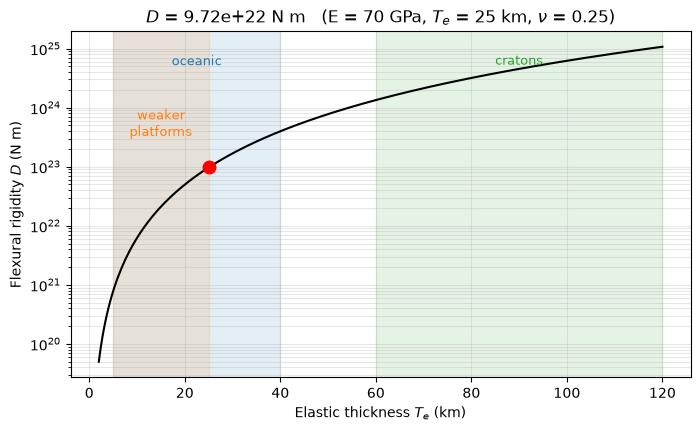

In [2]:
# Section 1: flexural rigidity. The red dot is your plate; shaded bands are typical Te ranges.
interact(plot_rigidity,
         E_GPa=FloatSlider(value=70, min=50, max=120, step=5, description='E (GPa)', style=STYLE),
         Te_km=FloatSlider(value=25, min=5, max=100, step=1, description='Te (km)', style=STYLE),
         nu=FloatSlider(value=0.25, min=0.20, max=0.35, step=0.01, description='ν (Poisson)', style=STYLE));

### Elastic properties of crustal provinces

The large differences in rigidity between tectonic provinces come mainly from differences in **elastic thickness $T_e$**, not Young's modulus. $E$ and $\nu$ vary by only tens of percent between rock types, whereas $T_e$ varies by more than an order of magnitude and enters $D$ cubed. $T_e$ reflects the thermal state and composition of the lithosphere. For oceanic lithosphere it roughly tracks the depth of the ~300–600 °C isotherm at the time of loading, so it increases with plate age (Watts, 2001).

| Province | $E$ (GPa) | $\nu$ | Typical $T_e$ (km) | Notes |
|----------|-----------|-------|--------------------|-------|
| **Oceans** (oceanic lithosphere) | 70–100 | 0.25–0.30 | 5–40 | Basalt and gabbro over mantle; $T_e$ increases with age at the time of loading |
| **Cratons** (ancient, stable parts of continents) | 70–100 | 0.23–0.28 | 60–100+ | Cold, thick lithospheric roots; the high values are debated |
| **Weaker platforms** (younger, deformed, or extended parts of continents) | 70–100 | 0.24–0.29 | 5–30 | Warmer, thinner lithosphere, e.g., rifts and young orogens |

These values are approximate and vary with local geological conditions. They come from laboratory measurements on rock samples, gravity and topography studies, and modeling (Turcotte & Schubert, 2014; Watts, 2001; Watts & Burov, 2003).

### Poisson's ratio ($\nu$)

Poisson's ratio is the ratio of lateral (transverse) strain to axial strain, taken with a minus sign so that it is positive: stretch a rock vertically and it contracts horizontally. Most rocks have $\nu \approx 0.2$–$0.3$. A value of $\nu = 0.5$ means the material is incompressible: its volume does not change as it deforms. Because $\nu$ enters $D$ only through $1-\nu^2$, the range of values in the table changes $D$ by less than 5%. That is why $\nu = 0.25$ is used almost universally (Turcotte & Schubert, 2014; Jaeger et al., 2007).

## 2. Flexural Parameter and Characteristic Wavelength

### Definition:

The horizontal length scale of flexure is set by the **flexural parameter** $\alpha$:

$$ \alpha = \left( \frac{4D}{(\rho_m - \rho_{infill})\, g} \right)^{1/4} $$

A loaded plate bends into a damped wave. Its **flexural wavelength** $\lambda = 2\pi\alpha$ is the distance between successive crests (or troughs). Successive points of zero deflection are half a wavelength ($\pi\alpha$) apart. In tectonics, $\alpha$ controls foreland basin width and the distance to the forebulge.

| Variable | Description | Typical value | Units |
|----------|-------------|---------------|-------|
| $D$      | Flexural rigidity | calculated (Section 1) | N m |
| $\rho_m$ | Mantle density | 3300 | kg/m³ |
| $\rho_{infill}$ | Density of the material filling the flexural depression | 0 (air), 1000 (water), 2000–2600 (sediment) | kg/m³ |
| $g$      | Gravity | 9.81 | m/s² |

The restoring force comes from replacing mantle with lighter infill. So the density that matters is the **contrast** $\rho_m - \rho_{infill}$, not the mantle density alone.

### Where are the foredeep and forebulge?

| Quantity | Continuous plate | Broken plate |
|----------|------------------|--------------|
| Foredeep width (first zero crossing), $x_0$ | $3\pi\alpha/4$ | $\pi\alpha/2$ |
| Forebulge crest, $x_b$ | $\pi\alpha$ | $3\pi\alpha/4$ |
| Forebulge height, $\lvert w_b \rvert$ | $e^{-\pi} w_0 \approx 0.043\,w_0$ | $e^{-3\pi/4} w_0/\sqrt{2} \approx 0.067\,w_0$ |

Here $w_0$ is the deflection at the load (Section 3). The forebulge crest lies *beyond* the zero crossing, so the edge of the foredeep is not the top of the forebulge.

*Note: some texts define a characteristic wavelength $2\pi[D/((\rho_m-\rho_{infill})g)]^{1/4} = \lambda/\sqrt{2}$, the load wavelength at which a periodic load is half compensated. This notebook uses $\lambda = 2\pi\alpha$ throughout.*

> 🔮 **Predict:** $\alpha \propto D^{1/4}$. If $D$ increases 10×, how much farther away is the forebulge? If the foredeep fills with sediment instead of water, does the forebulge move toward or away from the thrust front?

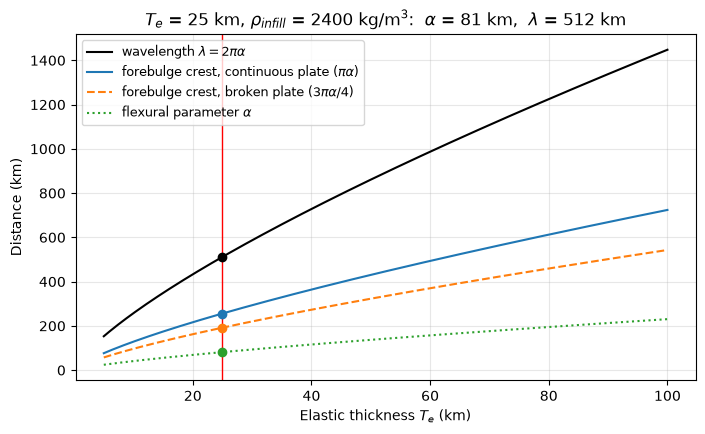

In [3]:
# Section 2: how far does flexure reach? Dots mark the values for the chosen Te.
interact(plot_wavelength,
         Te_km=FloatSlider(value=25, min=5, max=100, step=1, description='Te (km)', style=STYLE),
         E_GPa=FloatSlider(value=70, min=50, max=120, step=5, description='E (GPa)', style=STYLE),
         rho_infill=FloatSlider(value=2400, min=0, max=2800, step=100,
                                description='ρ_infill (kg/m³)', style=STYLE),
         nu=FloatSlider(value=0.25, min=0.20, max=0.35, step=0.01, description='ν (Poisson)', style=STYLE));

## 3. Lithospheric Flexure Under a Thrust Load

Lithospheric flexure is the bending of the lithosphere under a load. Following Turcotte & Schubert (2014, ch. 3), we treat the orogenic wedge as a **line load** $V_0$ (weight per unit length along strike, N/m) applied at the thrust front, $x = 0$. The foreland is $x > 0$.

**Continuous plate** (plate unbroken beneath the load):

$$ w(x) = w_0\, e^{-x/\alpha}\left(\cos\frac{x}{\alpha} + \sin\frac{x}{\alpha}\right), \qquad w_0 = \frac{V_0\,\alpha^3}{8D} $$

**Broken plate** (plate ends beneath the load):

$$ w(x) = w_0\, e^{-x/\alpha}\cos\frac{x}{\alpha}, \qquad w_0 = \frac{V_0\,\alpha^3}{4D} $$

Both use $\alpha$ from Section 2. **Units check:** $V_0\alpha^3/D$ = (N/m)(m³)/(N m) = m ✓. (As in Turcotte & Schubert, the broken-plate $w_0$ assumes the load is shared by the two broken plate ends. If the whole load rests on one plate end, $w_0$ doubles.)

**Which plate model?** A plate that stays continuous beneath the load is the classic textbook case. For foreland basins, the underthrust plate may be effectively broken, or strongly weakened, beneath the orogen. Lyon-Caen & Molnar (1985) modeled the Indian plate beneath the Himalaya this way. For the same $T_e$ and load, the two models give different basin depths and forebulge positions, so try both.

**The load.** We approximate the wedge as a triangle of height $H$ (at the hinterland) and width $W$ (from hinterland to thrust front), made of rock of density $\rho_{load}$ = 2700 kg/m³:

$$ V_0 = \rho_{load}\, g\, \tfrac{1}{2} H W $$

Lumping the whole wedge into a line load at the thrust front is a first-order approximation. A real, distributed wedge changes both the depth at the front and the forebulge position somewhat.

**The infill.** Sediment (or water) filling the flexural depression enters through $\rho_{infill}$ in $\alpha$. The restoring force per unit deflection is $(\rho_m-\rho_{infill})g$. Do not add the basin fill as a separate load on top: $\alpha$ already accounts for it, so that would count it twice.

> 🔮 **Predict before you move the sliders:**
> 1. If you double the wedge height $H$, what happens to the foredeep depth? To the forebulge position?
> 2. If you switch from a continuous to a broken plate, is the basin deeper or shallower? Is the forebulge closer or farther?
> 3. If the foredeep is filled with water (1000 kg/m³) instead of sediment (2400 kg/m³), how do its depth and width change?

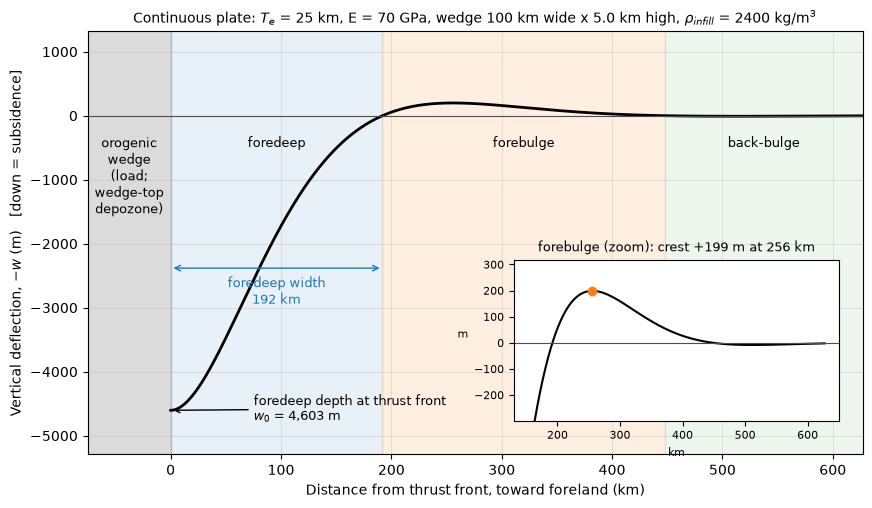

In [4]:
# Section 3: foreland basin profile. The inset magnifies the forebulge (it is only ~4-7% of the foredeep depth).
interact(plot_flexure,
         Te_km=FloatSlider(value=25, min=5, max=100, step=1, description='Te (km)', style=STYLE),
         E_GPa=FloatSlider(value=70, min=50, max=120, step=5, description='E (GPa)', style=STYLE),
         H_km=FloatSlider(value=5, min=0.5, max=8, step=0.5, description='wedge height H (km)', style=STYLE),
         W_km=FloatSlider(value=100, min=20, max=300, step=10, description='wedge width W (km)', style=STYLE),
         rho_infill=FloatSlider(value=2400, min=0, max=2800, step=100,
                                description='ρ_infill (kg/m³)', style=STYLE),
         plate=Dropdown(options=['continuous', 'broken'], value='continuous', description='plate'),
         nu=fixed(0.25));

# For numbers instead of a plot, e.g.:  flexure_summary(Te_km=25, plate='broken')

## 4. Applications to Fold-Thrust Belts

In fold-thrust belts like the Himalaya or the North American Cordillera (e.g., the Sevier belt; DeCelles & Mitra, 1995), the thrust load flexes the foreland plate and creates a foreland basin system. The system has four depozones: wedge-top, foredeep, forebulge, and back-bulge (DeCelles & Giles, 1996). Use the model above to simulate this. For the Himalaya, for example, start with $T_e$ = 25 km and a wedge ~100 km wide and ~5 km high, then compare the basin dimensions to observed values (~200–300 km; Kapp & DeCelles, 2019).

### Time Dimension

The elastic response to a load is effectively instantaneous, but foreland basins evolve over Myr timescales as the load grows, advances toward the foreland, and erodes. Use crustal thickness data (e.g., Sundell et al., 2021) to estimate load timing. Then simulate a time-varying load by stepping $H$ (or $W$) through a sequence of values.

### Climate Link

Climate can also affect flexural basin evolution. Which parameters would be modified by enhanced erosion?

## 5. Guided Exercises

### Exercise 1: Trends in Flexural Rigidity

Using the table in Section 1 (and the slider or the `rigidity()` function), provide reasonable values for flexural rigidity for oceanic lithosphere, cratonic regions, and weaker platforms. What trends do you observe? Which parameter controls most of the variation?

*Your Answer Here:*

### Exercise 2: Factors Controlling Wavelength

What factors control the characteristic wavelength of flexure? What conditions would favor shorter versus longer wavelengths? (Use the Section 2 plot to check your reasoning.)

*Your Answer Here:*

### Exercise 3: Himalayan Foreland Simulation

Use the Section 3 model (sliders, or `plot_flexure(...)` and `flexure_summary(...)`) with reasonable parameters for India just south of the Himalaya. Given that India's forebulge is located ~300 km south of the Himalayan foothills, does this simple flexural relationship reasonably approximate the foreland basin width? How deep would you expect the foredeep basin to be adjacent to the Main Frontal Thrust? Does your answer depend on the plate model you choose?

*Your Answer Here:*

### Exercise 4: Hypothesis Testing

The plot below compares $T_e$ = 15, 25, and 35 km. Does a stiffer plate (higher $T_e$) produce a wider, shallower basin? Then test the effect of basin fill by re-running with `rho_infill=1000` (water-filled, underfilled basin) and `rho_infill=2400` (sediment-filled), and compare `plate='continuous'` with `plate='broken'`.

*Modify the code below as needed and interpret:*

### Exercise 5: Erosion Impact

Erosion reduces load over time (Molnar & England, 1990). Decrease the wedge height $H$ by 20% and observe the basin shallowing. What happens to the forebulge position? What would this create in the sedimentary record?

*Your Answer Here:*

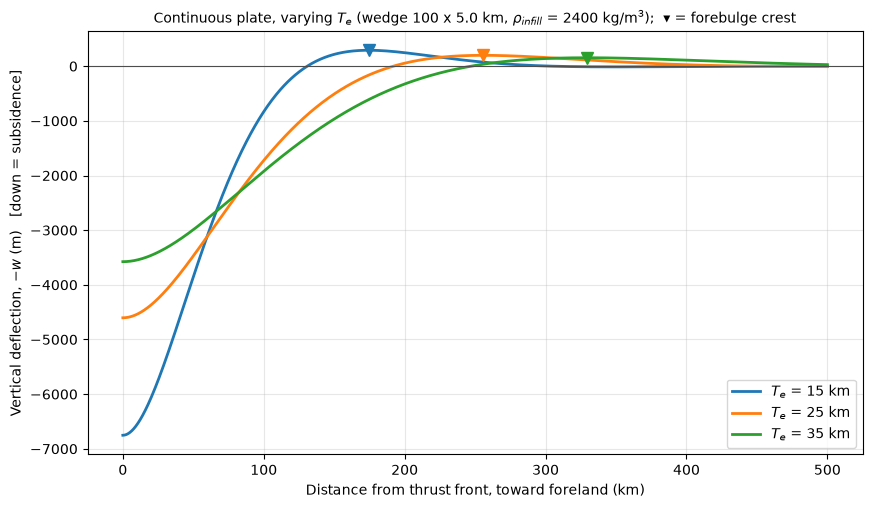

In [5]:
# Exercise 4: edit the arguments and re-run, e.g.
#   multi_flexure_plot(Te_list=(15, 25, 35), rho_infill=1000)
#   multi_flexure_plot(Te_list=(15, 25, 35), plate='broken')
multi_flexure_plot(Te_list=(15, 25, 35))

## Sources

1. DeCelles, P. G., & Giles, K. A. (1996). Foreland basin systems. *Basin Research*, 8(2), 105–123. https://doi.org/10.1046/j.1365-2117.1996.01491.x
2. DeCelles, P. G., & Mitra, G. (1995). History of the Sevier orogenic wedge in terms of critical taper models, northeast Utah and southwest Wyoming. *Geological Society of America Bulletin*, 107(4), 454–462. https://doi.org/10.1130/0016-7606(1995)107<0454:HOTSOW>2.3.CO;2
3. England, P., & Molnar, P. (1990). Surface uplift, uplift of rocks, and exhumation of rocks. *Geology*, 18(12), 1173–1177. https://doi.org/10.1130/0091-7613(1990)018<1173:SUUORA>2.3.CO;2
4. Jaeger, J. C., Cook, N. G. W., & Zimmerman, R. W. (2007). *Fundamentals of Rock Mechanics* (4th ed.). Blackwell Publishing.
5. Kapp, P., & DeCelles, P. G. (2019). Mesozoic–Cenozoic geological evolution of the Himalayan-Tibetan orogen and working tectonic hypotheses. *American Journal of Science*, 319(3), 159–254. https://doi.org/10.2475/03.2019.01
6. Lyon-Caen, H., & Molnar, P. (1985). Gravity anomalies, flexure of the Indian plate, and the structure, support and evolution of the Himalaya and Ganga Basin. *Tectonics*, 4(6), 513–538. https://doi.org/10.1029/TC004i006p00513
7. Molnar, P., & England, P. (1990). Late Cenozoic uplift of mountain ranges and global climate change: chicken or egg? *Nature*, 346, 29–34. https://doi.org/10.1038/346029a0
8. Sundell, K. E., Laskowski, A. K., Kapp, P. A., Ducea, M. N., & Chapman, J. B. (2021). Jurassic to Neogene quantitative crustal thickness estimates in southern Tibet. *GSA Today*, 31(6). https://doi.org/10.1130/GSATG461A.1
9. Turcotte, D. L., & Schubert, G. (2014). *Geodynamics* (3rd ed.). Cambridge University Press.
10. Watts, A. B. (2001). *Isostasy and Flexure of the Lithosphere*. Cambridge University Press.
11. Watts, A. B., & Burov, E. B. (2003). Lithospheric strength and its relationship to the elastic and seismogenic layer thickness. *Earth and Planetary Science Letters*, 213(1–2), 113–131. https://doi.org/10.1016/S0012-821X(03)00289-9